In [1]:
# ! python -m pip install "numpy==1.23.5" "matplotlib==3.7.5" "ipython==8.18.1" "ipympl==0.9.4"

In [2]:
%matplotlib widget

In [3]:
import numpy as np
from dezero import Variable
import dezero.functions as F

# 追加ライブラリ
import matplotlib.pyplot as plt
from matplotlib.animation import FuncAnimation

In [4]:
# 데이터 수 지정
N = 100

# 장난감 데이터 생성
x_data = np.random.rand(N)
y_data = 5 + 2 * x_data + np.random.rand(N)
print(np.round(x_data[:10], 2))
print(np.round(y_data[:10], 2))

[0.05 0.99 0.39 0.22 0.42 0.05 0.23 0.2  0.49 0.17]
[5.47 7.39 6.03 6.02 6.22 5.58 5.69 5.78 6.51 5.57]


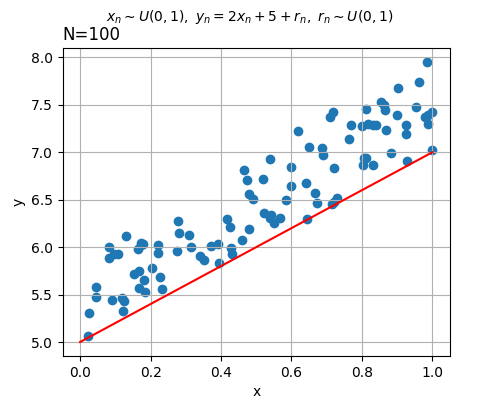

In [ ]:
# 토이 데이터셋의 산점도 생성
plt.figure(figsize=(5, 4), facecolor='white')
plt.scatter(x_data, y_data)
plt.xlabel('x')
plt.ylabel('y')
plt.title('N=' + str(N), loc='left')
plt.suptitle('$x_n \sim U(0, 1),\ y_n = 2 x_n + 5 + r_n,\ r_n \sim U(0, 1)$', fontsize=10)
plt.grid()
plt.show()

In [6]:
# 반복 횟수 지정
iters = 100

# 학습률 지정
lr = 0.1

# 토이 데이터셋을 Variable 인스턴스로 변환
x = Variable(x_data.reshape(N, 1))
y = Variable(y_data.reshape(N, 1))

# 파라미터 초기화
W = Variable(np.zeros((1, 1)))  # 가중치
b = Variable(np.zeros(1))  # 파라미터

# 학습 과정 확인용 리스트 초기화
trace_loss = []
trace_W = [W.data.item()]
trace_b = [b.data.item()]

# 반복 학습
for i in range(iters):
    # 예측값(선형 변환) 계산
    y_pred = F.linear(x, W, b)
    
    # 손실 계산
    loss = F.mean_squared_error(y, y_pred)
    
    # 기울기 초기화
    W.cleargrad()
    b.cleargrad()
    
    # 기울기(역전파) 계산
    loss.backward()
    
    # 경사 하강법으로 값 업데이트
    W.data -= lr * W.grad.data
    b.data -= lr * b.grad.data
    
    # 업데이트된 값 저장
    trace_loss.append(loss.data)
    trace_W.append(W.data.item())
    trace_b.append(b.data.item())
    
    # 손실 출력
    print('iter ' + str(i + 1) + ': loss=' + str(loss.data))

iter 1: loss=42.67358495239765
iter 2: loss=23.485519957475297
iter 3: loss=12.947562570431703
iter 4: loss=7.159967050752764
iter 5: loss=3.981124000395411
iter 6: loss=2.234933295489633
iter 7: loss=1.2755199965183612
iter 8: loss=0.7481909866606496
iter 9: loss=0.45816040849007966
iter 10: loss=0.2984580949896529
iter 11: loss=0.2103393077173625
iter 12: loss=0.16154309819335552
iter 13: loss=0.13435253200989455
iter 14: loss=0.11903776581991844
iter 15: loss=0.11025520583372642
iter 16: loss=0.10507004672272363
iter 17: loss=0.10187031637189876
iter 18: loss=0.09977050562360976
iter 19: loss=0.09828406161466793
iter 20: loss=0.09714353194886663
iter 21: loss=0.09620179374074195
iter 22: loss=0.09537781174487209
iter 23: loss=0.09462685036430116
iter 24: loss=0.09392411491073396
iter 25: loss=0.09325576776234465
iter 26: loss=0.09261399457167808
iter 27: loss=0.09199429462924216
iter 28: loss=0.09139399266295861
iter 29: loss=0.0908114214133884
iter 30: loss=0.0902454725806471
iter 

In [7]:
# 예측값을 계산
y_pred = F.linear(x, W, b)
print(np.round(y_pred.data[:10].flatten(), 3))

# 손실을 계산
last_loss = F.mean_squared_error(y, y_pred).data
print(last_loss)

[5.4   7.547 6.191 5.802 6.263 5.4   5.812 5.762 6.414 5.673]
0.07290168026440184


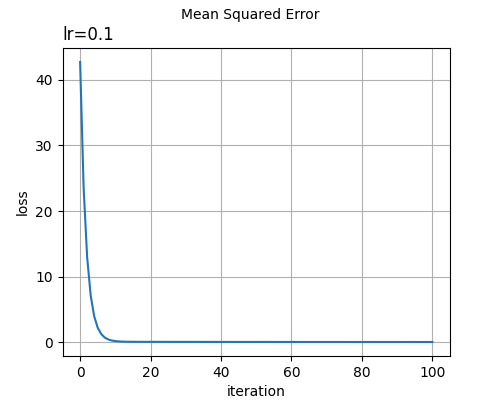

In [8]:
# 손실 함수의 추이를 그래프로 작성
plt.figure(figsize=(5, 4), facecolor='white')
plt.plot(np.arange(iters+1), trace_loss+[last_loss])
plt.xlabel('iteration')
plt.ylabel('loss')
plt.suptitle('Mean Squared Error', fontsize=10)
plt.title('lr='+str(lr), loc='left')
plt.grid()
plt.show()

In [9]:
# 회귀 직선 계산
x_line = np.linspace(0, 1, num=101)
y_line = F.linear(x_line.reshape((-1, 1)), W, b).data.flatten()
print(np.round(x_line[:10], 3))
print(np.round(y_line[:10], 3))

[0.   0.01 0.02 0.03 0.04 0.05 0.06 0.07 0.08 0.09]
[5.294 5.317 5.34  5.363 5.386 5.408 5.431 5.454 5.477 5.5  ]


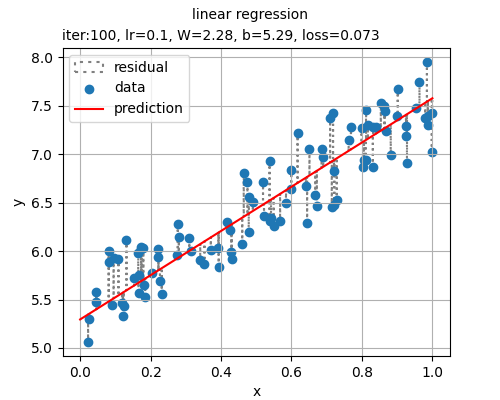

In [10]:
# 잔차 계산
y_residual = y_pred.data.flatten() - y_data

# 파라미터 라벨 생성
param_label = 'iter:' + str(iters)
param_label += ', lr=' + str(lr)
param_label += ', W=' + str(np.round(W.data.item(), 2))
param_label += ', b=' + str(np.round(b.data.item(), 2))
param_label += ', loss=' + str(np.round(last_loss, 3))

# 회귀 직선 그리기
plt.figure(figsize=(5, 4), facecolor='white')
plt.quiver(
    x_data, y_data, np.repeat(0, N), y_residual,
    scale_units='xy', scale=1, units='dots', width=0.1,
    headwidth=0.1, fc='none', ec='gray', linewidth=1.5,
    linestyle=':', label='residual'
)
plt.scatter(x_data, y_data, label='data')
plt.plot(x_line, y_line, color='red', label='prediction')
plt.xlabel('x')
plt.ylabel('y')
plt.suptitle('linear regression', fontsize=10)
plt.title(param_label, loc='left', fontsize=10)
plt.grid()
plt.legend()
plt.show()

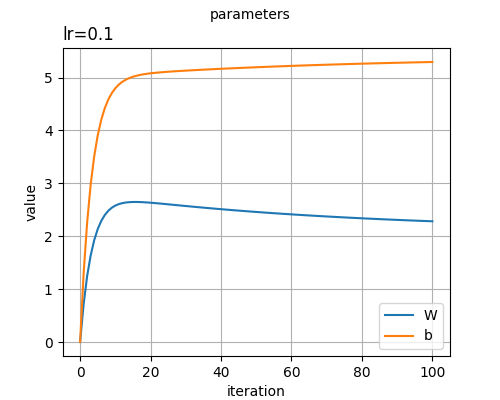

In [11]:
# 파라미터 갱신값의 변화 추이를 그래프로 표시
plt.figure(figsize=(5, 4), facecolor='white')
plt.plot(np.arange(iters+1), trace_W, label='W')
plt.plot(np.arange(iters+1), trace_b, label='b')
plt.xlabel('iteration')
plt.ylabel('value')
plt.suptitle('parameters', fontsize=10)
plt.title('lr='+str(lr), loc='left')
plt.grid()
plt.legend()
plt.show()